# Multi Seed Results:

In [1]:
import numpy as np
import random
import pandas as pd

In [2]:
# Hyperparameters we selected

Episodic_M_grid = [(1e-06, 0.01, 0.9, 0.2)]
Continuing_UM_grid = [(1e-06, 0.0005, 0.8, 0.2)]
Average_Reward_UM_grid = [(1e-06, 0.001, 0.0001, 0.2)]
Average_Reward_M_grid = [(1e-06, 0.005, 0.0005, 0.2)]

seed = 243
random.seed(seed)
np.random.seed(seed)
seeds = np.random.choice(100000, size=1000, replace=False).tolist()

k = 11
n = int(k*(k-1)/2)
max_it = 50000

In [4]:
Names = ["Episodic_M_R",
        "Continuing_UM_R",
        "Average_reward_UM_R",
        "Average_reward_M_R"]

N = { "Episodic_M_R" : 0,
      "Continuing_UM_R" : 1,
      "Average_reward_UM_R" : 2,
      "Average_reward_M_R" : 3
    }

MS = []

for name in Names:
  path = name + ".csv"
  A = pd.read_csv(path)
  MS.append(A[['seed', 'r_d', 'w_b','n_it']])

In [5]:
a = [(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0, 0) for i in range(4)]
MS_results = pd.DataFrame(a, index = Names,
                 columns=['r_d_mean', 'r_d_std', 'r_d_max',
                          'w_b_mean', 'w_b_std', 'w_b_max',
                          'exact', 'it_maxed'])
for name in Names:
    df = MS[N[name]]
    r_d = df['r_d']
    w_b = df['w_b']
    r_d_mean = np.mean(r_d)
    r_d_std = np.std(r_d)
    r_d_max = np.max(r_d)
    w_b_mean = np.mean(w_b)
    w_b_std = np.std(w_b)
    w_b_max = np.max(w_b)
    exact = sum(w_b == 0)
    it_maxed = sum(df['n_it'] == max_it)
    MS_results.loc[name] = [r_d_mean, r_d_std, r_d_max,
                            w_b_mean, w_b_std, w_b_max,
                            exact, it_maxed]

In [6]:
print(MS_results)
round(MS_results[['r_d_mean', 'w_b_mean', 'exact', 'it_maxed']], 5)

                     r_d_mean   r_d_std  r_d_max  w_b_mean   w_b_std  w_b_max  \
Episodic_M_R         0.009567  0.008270  0.04787     2.404  1.535182      7.0   
Continuing_UM_R      0.003404  0.004967  0.04720     1.351  1.247317      7.0   
Average_reward_UM_R  0.006824  0.006284  0.03276     2.013  1.430675      8.0   
Average_reward_M_R   0.008662  0.008587  0.06188     2.211  1.533127      8.0   

                     exact  it_maxed  
Episodic_M_R            91      1000  
Continuing_UM_R        285         3  
Average_reward_UM_R    149      1000  
Average_reward_M_R     123      1000  


,r_d_mean,w_b_mean,exact,it_maxed
Episodic_M_R,0.00957,2.404,91,1000
Continuing_UM_R,0.00340,1.351,285,3
Average_reward_UM_R,0.00682,2.013,149,1000
Average_reward_M_R,0.00866,2.211,123,1000


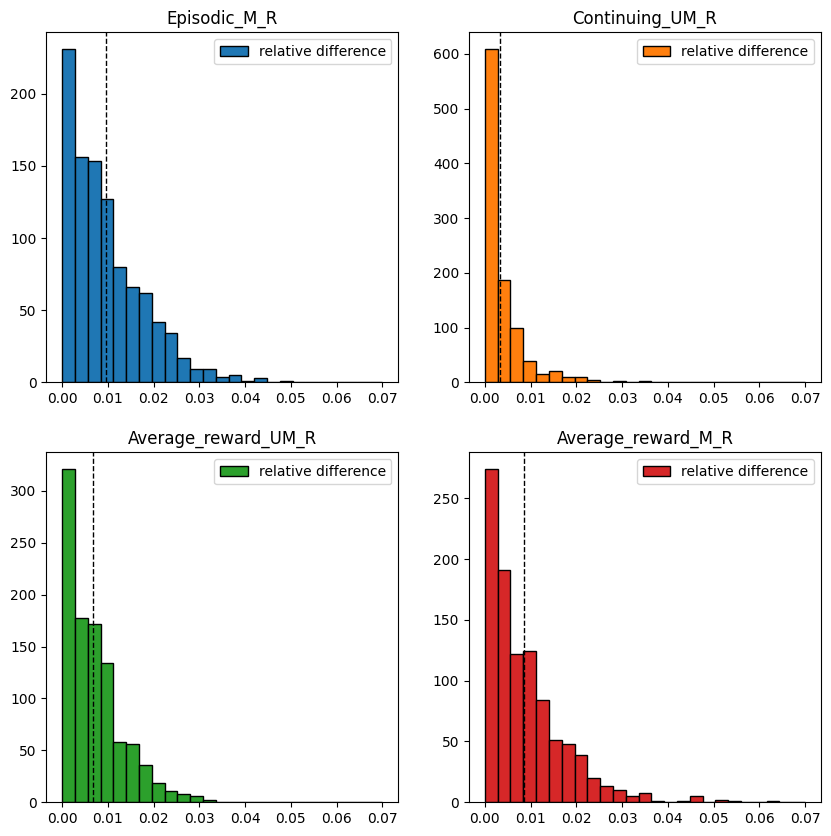

In [7]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10,10)

Color = {
    0 : 'tab:blue',
    1 : 'tab:orange',
    2 : 'tab:green',
    3 : 'tab:red',
}

for name in Names:
  i = N[name]
  color = Color[i]
  df = MS[i]['r_d']
  plt.subplot(2, 2, i+1)
  plt.title(name)
  plt.hist(df, bins = 25, range = [0, 0.07], label = "relative difference", histtype = 'bar', color = color, edgecolor = 'black')
  plt.axvline(df.mean(), color='k', linestyle='dashed', linewidth=1)
  plt.legend()

# plt.figure()
# for name in Names:
#   i = N[name]
#   plt.hist(MS[i]['r_d'], bins = 25, range = [0, 0.07], label = name)
# plt.legend()

<Axes: >

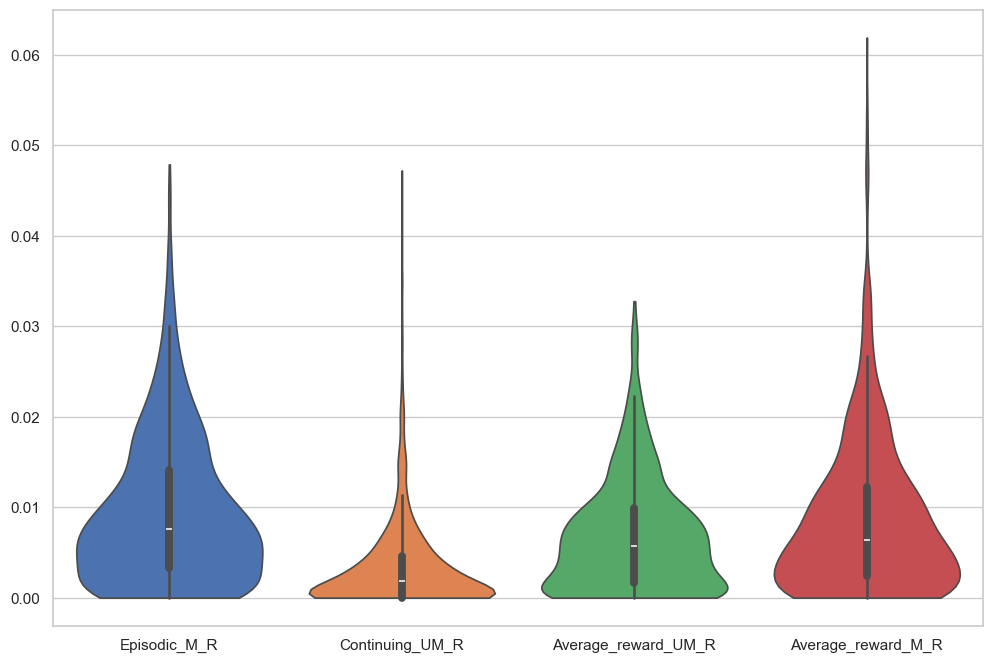

In [11]:
import seaborn as sb

sb.set(style = 'whitegrid')

# loading data-set
tip = sb.load_dataset('tips')
plt.figure(figsize=(12,8))

V = pd.DataFrame(np.zeros([1000, 4]), columns = Names)

for name in Names:
  i = N[name]
  V[name] = MS[i]['r_d']

sb.violinplot(V, native_scale=True, cut = 0, saturation = 1)

In [12]:
name = "Continuing_UM_R"
df = MS[N[name]]
n_it = df['n_it']
Extra = pd.DataFrame([(0.0, 0.0, 0.0)], index = [name],
                 columns=['n_it_mean', 'n_it_std','n_it_min'])
Extra.loc[name] = [np.mean(n_it), np.std(n_it), np.min(n_it)]
print(Extra)

                 n_it_mean    n_it_std  n_it_min
Continuing_UM_R  35329.821  4031.81069   22058.0


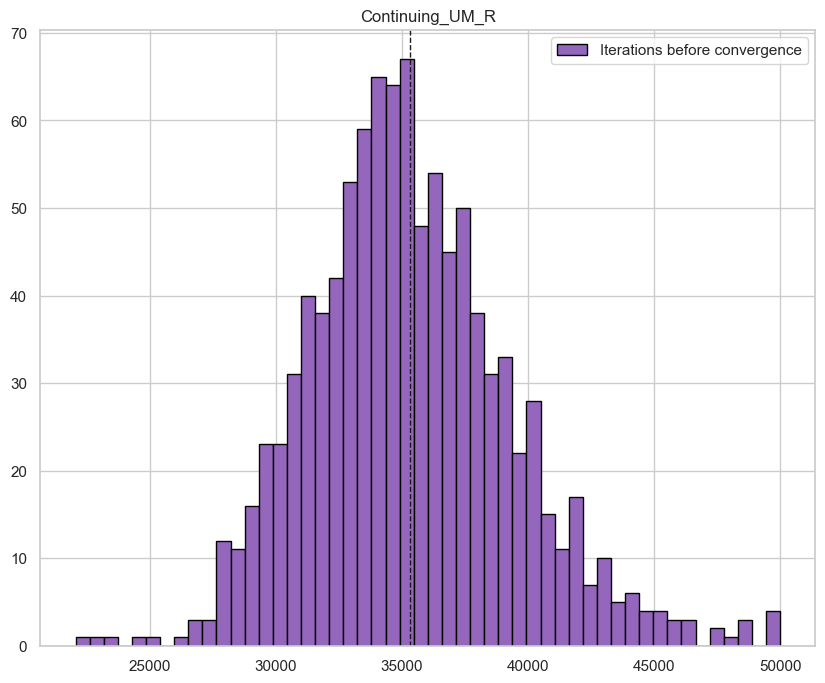

In [13]:
i = 1
df = MS[i]['n_it']
plt.rcParams["figure.figsize"] = (10,8)
plt.title(name)
plt.hist(df, bins = 50, label = "Iterations before convergence", histtype = 'bar', color = 'tab:purple', edgecolor = 'black')
plt.axvline(df.mean(), color='k', linestyle='dashed', linewidth=1)
plt.legend()

In [14]:
# Shapiro-Wilk Test
from scipy.stats import shapiro

stat, p = shapiro(df)
print('Statistic = %.6f, p = %.12f' % (stat, p))

alpha = 0.05
if p > alpha:
    print('Sample looks Gaussian (fail to reject H0)')
else:
    print('Sample does not look Gaussian (reject H0)')

Statistic = 0.985034, p = 0.000000013559
Sample does not look Gaussian (reject H0)


In [15]:
# D'Agostino, Pearson Test
from scipy.stats import normaltest

stat, p = normaltest(df)
print('Statistic = %.6f, p = %.12f' % (stat, p))

alpha = 0.05
if p > alpha:
    print('Sample looks Gaussian (fail to reject H0)')
else:
    print('Sample does not look Gaussian (reject H0)')

Statistic = 49.711315, p = 0.000000000016
Sample does not look Gaussian (reject H0)
